# Interpretacion del experimento internacional
Interpreta el comportamiento del modelo seleccionado sin convertir un pronostico del TSI provisional en una afirmacion causal o en una etiqueta de pre-colapso.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / 'data').exists() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent
MODEL_DIR = PROJECT_ROOT / 'data' / '04_model_output' / 'modeling'
VALIDATION_DIR = PROJECT_ROOT / 'data' / '04_model_output' / 'validation'
metrics = pd.read_csv(MODEL_DIR / 'metricas_modelos.csv')
tests = pd.read_csv(MODEL_DIR / 'pruebas_modelos_vs_baseline.csv')
by_source = pd.read_csv(VALIDATION_DIR / 'metricas_por_fuente.csv')
predictions = pd.read_csv(MODEL_DIR / 'predicciones_prueba.csv', parse_dates=['fecha'])
predictions['abs_random_forest'] = (predictions['real'] - predictions['random_forest']).abs()
predictions['abs_baseline'] = (predictions['real'] - predictions['baseline_persistencia']).abs()
display(metrics)
display(tests)
display(by_source)

,modelo,mae,rmse,r2
0,random_forest,2.511087,5.274513,0.947871
1,ridge,3.514525,6.338738,0.924712
2,baseline_persistencia,5.302138,9.950087,0.814488


,modelo,mejora_mae_vs_baseline,t_pareada_p_valor,wilcoxon_p_valor
0,ridge,1.787612,9.673231e-31,1.372203e-21
1,random_forest,2.791051,2.731364e-64,1.632495e-113


,fuente_original,filas_prueba,mae_baseline,mae_random_forest,rmse_baseline,rmse_random_forest,mejora_mae,mejora_relativa_pct
0,istanbul_traffic_index,665.0,12.113811,5.370551,16.285460,8.305310,6.743260,55.665883
1,madrid_traffic_points,5.0,0.248895,0.946630,0.306946,0.991827,-0.697736,-280.333651
2,metr_la,23.0,12.689391,10.807494,21.619667,16.364016,1.881897,14.830472
3,pems_bay,35.0,3.112371,0.624970,3.749540,1.081918,2.487401,79.919814
4,sao_paulo_cet,1218.0,1.527293,0.853842,2.036309,1.301546,0.673451,44.094419


In [2]:
residuals = predictions.assign(
    residual_random_forest=lambda frame: frame['real'] - frame['random_forest'],
    residual_baseline=lambda frame: frame['real'] - frame['baseline_persistencia'],
)
residual_summary = residuals.groupby('fuente_original', as_index=False).agg(
    sesgo_rf=('residual_random_forest', 'mean'),
    error_rf_p95=('abs_random_forest', lambda values: values.quantile(0.95)),
    error_rf_mediana=('abs_random_forest', 'median'),
    predicciones=('real', 'size'),
)
display(residual_summary)

,fuente_original,sesgo_rf,error_rf_p95,error_rf_mediana,predicciones
0,istanbul_traffic_index,-1.029447,18.023493,3.369512,665
1,madrid_traffic_points,0.946630,1.390174,0.843895,5
2,metr_la,-0.763730,31.726503,5.528083,23
3,pems_bay,0.086070,1.794381,0.295028,35
4,sao_paulo_cet,0.202997,2.752055,0.565381,1218


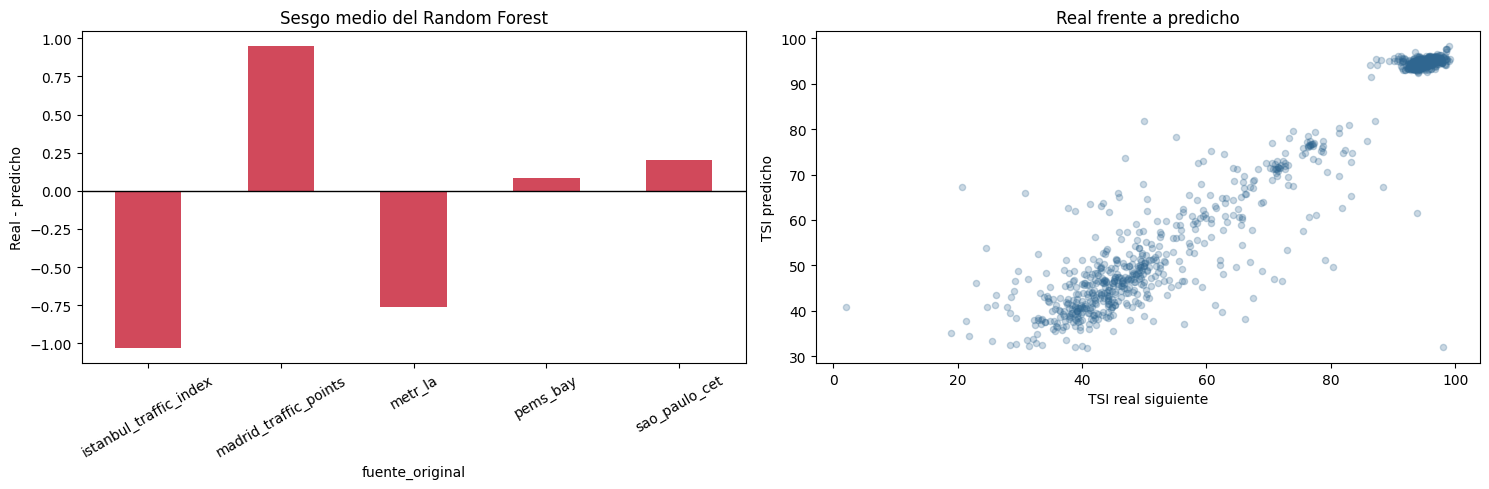

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
residual_summary.plot.bar(x='fuente_original', y='sesgo_rf', ax=axes[0], legend=False, color='#d1495b', rot=30)
axes[0].axhline(0, color='black', linewidth=1)
axes[0].set_title('Sesgo medio del Random Forest')
axes[0].set_ylabel('Real - predicho')
residuals.sample(min(len(residuals), 1500), random_state=42).plot.scatter(x='real', y='random_forest', ax=axes[1], alpha=0.25, color='#2f6690')
axes[1].set_title('Real frente a predicho')
axes[1].set_xlabel('TSI real siguiente')
axes[1].set_ylabel('TSI predicho')
plt.tight_layout()
plt.show()

## Lectura y limites
Random Forest supera la persistencia en el promedio y en cuatro fuentes. Madrid no confirma la mejora y dispone de solo cinco observaciones de prueba. El experimento predice el TSI provisional del siguiente dia; no demuestra causalidad, no mide pre-colapso y no sustituye calibracion local futura.